In [11]:
import numpy as np
import sinter
from matplotlib import pyplot as plt
from pathlib import Path
import pandas as pd
from scipy.stats import linregress
from stimbposd import BPOSD
import sinter
from src.generate_BBcode import BivBic

# The BivBic class

We create a ```BivBic``` instance by entering all the relevant code parameters. The circuit can be accesed as an attribute of the instance.

In [3]:
l = 6
m = 6
rounds =6

A_vars = [[0,3], [1,1], [1,2]]
B_vars = [[1,3], [0,1], [0,2]]

p = 0.006

In [4]:
code = BivBic(l = l,m = m,A_vars = A_vars,B_vars = B_vars,p = p,rounds = rounds)

In [5]:
circuit = code.circuit

We may also compute the code distance of this circuit by solving the appropriate sat optimization problem.

In [6]:
d = code.calculate_distance()
print(f"The code distance for this BB code is {d}")

The code distance for this BB code is 6


We may now sample and decode this circuit like any other stim circuit. In particular, we use the BP-OSD decoder from ```stimbposd``` as an example here.

In [7]:
nshots = 1000

circuit = code.circuit
sampler = circuit.compile_detector_sampler()
shots, observables = sampler.sample(nshots, separate_observables = True)

In [10]:
decoder = BPOSD(circuit.detector_error_model(), max_bp_iters=20)

predicted_observables = decoder.decode_batch(shots)
num_mistakes = np.sum(np.any(predicted_observables != observables, axis=1))

print(f"There were {num_mistakes} wrong predictions out of {nshots} shots.")

There were 118 wrong predictions out of 1000 shots.


## Some logical error rates computed for other BB codes.

Below we show some logical error rates computed for the well-known BB codes $[[72,12,6]], [[90,8,10]], [[108,8,10]]$, computed using the ```BivBic``` circuit.

In [13]:
SCRIPT_DIR = Path.cwd()
RESULTS_DIR = SCRIPT_DIR.parent/"results"

In [14]:
df = pd.read_csv(RESULTS_DIR / "Z_bposd.csv")

In [15]:
df

,shots,errors,discards,seconds,decoder,strong_id,json_metadata,custom_counts
0,1,0,0,0.008,bposd,9ad63f69b786318bbaffc81f089bbdb2e240ff42210544...,"{""basis"":""Z"",""code"":""bb72"",""d"":6,""k"":12,""n"":72...","{""detection_events"":19,""detectors_checked"":468}"
1,1,0,0,0.012,bposd,6b6db9e7f351ab22ec258435dcf76344289947ec659994...,"{""basis"":""Z"",""code"":""bb72"",""d"":6,""k"":12,""n"":72...","{""detection_events"":18,""detectors_checked"":468}"
2,1,0,0,0.012,bposd,6b6db9e7f351ab22ec258435dcf76344289947ec659994...,"{""basis"":""Z"",""code"":""bb72"",""d"":6,""k"":12,""n"":72...","{""detection_events"":18,""detectors_checked"":468}"
3,1,0,0,0.017,bposd,c387b0d706a7b02aac9be422acaded12772e96151822ae...,"{""basis"":""Z"",""code"":""bb72"",""d"":6,""k"":12,""n"":72...","{""detection_events"":22,""detectors_checked"":468}"
4,1,0,0,0.018,bposd,a1647e39adfdae2906f33ed7dd2c3bcbd320d61c1d89c7...,"{""basis"":""Z"",""code"":""bb72"",""d"":6,""k"":12,""n"":72...","{""detection_events"":52,""detectors_checked"":468}"
...,...,...,...,...,...,...,...,...
7886,5,0,0,0.930,bposd,b91aee81f5abcce37e3ce8b4aa94d4c7b72a2e0846aaba...,"{""basis"":""Z"",""code"":""bb108"",""d"":10,""k"":8,""n"":1...","{""detection_events"":396,""detectors_checked"":5670}"
7887,37,0,0,4.980,bposd,b91aee81f5abcce37e3ce8b4aa94d4c7b72a2e0846aaba...,"{""basis"":""Z"",""code"":""bb108"",""d"":10,""k"":8,""n"":1...","{""detection_events"":2813,""detectors_checked"":4..."
7888,5,0,0,1.120,bposd,b91aee81f5abcce37e3ce8b4aa94d4c7b72a2e0846aaba...,"{""basis"":""Z"",""code"":""bb108"",""d"":10,""k"":8,""n"":1...","{""detection_events"":418,""detectors_checked"":5670}"
7889,29,0,0,4.330,bposd,b91aee81f5abcce37e3ce8b4aa94d4c7b72a2e0846aaba...,"{""basis"":""Z"",""code"":""bb108"",""d"":10,""k"":8,""n"":1...","{""detection_events"":2006,""detectors_checked"":3..."


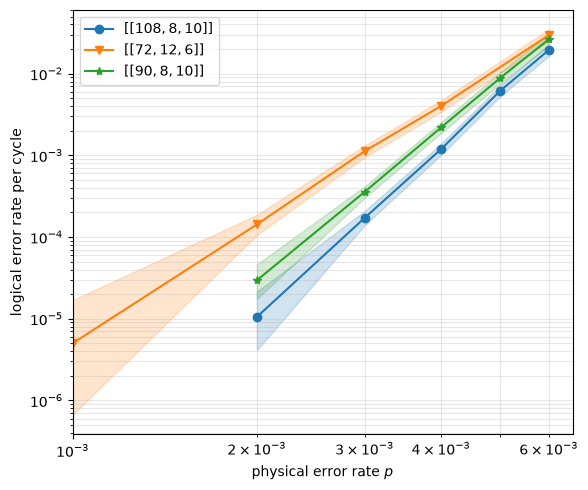

In [19]:
stats = sinter.read_stats_from_csv_files(RESULTS_DIR / "Z_bposd.csv")   # aggregates by strong_id

fig, ax = plt.subplots(figsize=(6, 5))

MAX_RATE = 0.25

KEEP = {"bb72", "bb90", "bb108"}

LABELS = {
    "bb72":  r"$[[72,12,6]]$",
    "bb90":  r"$[[90,8,10]]$",
    "bb108": r"$[[108,8,10]]$",
}
ORDER = ["bb72", "bb90", "bb108"]

def plot_filter(s: sinter.TaskStats) -> bool:
    if s.json_metadata.get("code") not in KEEP:
        return False
    n = s.shots - s.discards
    if n == 0:
        return False
    return (s.errors / n) <= MAX_RATE

sinter.plot_error_rate(
    ax=ax, stats=stats,
    filter_func=plot_filter,
    x_func=lambda s: s.json_metadata["p"],
    group_func=lambda s: LABELS[s.json_metadata["code"]],
    failure_units_per_shot_func=lambda s: s.json_metadata["rounds"],
    highlight_max_likelihood_factor=1000,
) 


ax.loglog()
ax.grid(which="both", alpha=0.3)
ax.set_xlabel("physical error rate $p$")
ax.set_ylabel("logical error rate per cycle")
ax.legend()
ax.set_xbound(0.001)
fig.savefig("bb_error_rates.png", dpi=150)
plt.tight_layout()
plt.show()


